# REPLICATION


In [1]:
import os, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels
import statsmodels.api as sm
from scipy import stats
from IPython.display import display
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.ardl import UECM
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import (acorr_breusch_godfrey, het_breuschpagan,
                                          linear_reset, breaks_cusumolsresid,
                                          recursive_olsresiduals)
from statsmodels.stats.outliers_influence import variance_inflation_factor
try:
    from arch.unitroot import PhillipsPerron
except ImportError:
    PhillipsPerron = None
    print("arch not installed: PP tests will be skipped (pip install arch)")

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
print("statsmodels", statsmodels.__version__)

statsmodels 0.14.5


In [2]:
DATA_DIR = Path(os.environ.get("BG_DATA_DIR", r"C:\Users\goits\Downloads\Data"))
REPLICATION_FILE = DATA_DIR / "Bulgaria Replication Data.csv"   
EXTENSION_FILE   = DATA_DIR / "Bulgaria Extension Data.csv"     
CARBON_FILE      = DATA_DIR / "Carbon Price.csv"                

EXT_START, EXT_END = "2014Q1", "2025Q4"     # extension window
PAPER_END = "2024Q2"                        # the paper's sample ends here
ALPHA = 0.05
TABLES = {}                                 # collected for export at the end

In [3]:
# Data helpers 
def partial_sums(x):
    """NARDL decomposition. First observation is the base (partial sums = 0), so no observation is lost."""
    dx = x.diff()
    pos = dx.clip(lower=0).fillna(0).cumsum()
    neg = dx.clip(upper=0).fillna(0).cumsum()
    return pos, neg

def read_quarterly(path, time_col):
    d = pd.read_csv(path)
    d.index = pd.PeriodIndex(d[time_col].astype(str).str.replace("-", "", regex=False), freq="Q")
    return d.drop(columns=[time_col]).sort_index()

def stl_adjust(s):
    """Remove the seasonal component with a robust STL decomposition (period = 4)."""
    return pd.Series(s.values - STL(s.values, period=4, robust=True).fit().seasonal, index=s.index)

def make_nardl_frame(raw, seasonal_adjust=False):
    d = raw[["GHG", "MAN", "CON", "GDPPC"]].copy()
    if seasonal_adjust:
        for v in ["GHG", "GDPPC"]:
            d[v] = stl_adjust(d[v])
    d["MAN_pos"], d["MAN_neg"] = partial_sums(d["MAN"])
    d["GDPPC_pos"], d["GDPPC_neg"] = partial_sums(d["GDPPC"])
    d["Dum"] = [1.0 if str(q) in ("2020Q1", "2020Q2") else 0.0 for q in d.index]   # COVID dummy, as in the paper
    for k in (2, 3, 4):
        d[f"Q{k}"] = (d.index.quarter == k).astype(float)                          # quarter dummies (Q1 = base)
    return d

def check_continuity(d, label=""):
    full = pd.period_range(d.index.min(), d.index.max(), freq="Q")
    ok = full.equals(d.index)
    print(f"{label}: {len(d)} quarters, {d.index.min()} to {d.index.max()}, continuous: {ok}")
    return ok

In [4]:
# ECM engine 
def ecm_columns(y, xvars, p, q):
    q = {x: q for x in xvars} if isinstance(q, (int, np.integer)) else dict(q)
    cols = [f"{y}_L1"] + [f"{x}_L1" for x in xvars]
    cols += [f"d{y}_L{i}" for i in range(1, p)]
    for x in xvars:
        cols += [f"d{x}_L{k}" for k in range(q[x])]
    return cols, q

def column_bank(df, y, xvars, pmax, qmax):
    cols = {f"{y}_L1": df[y].shift(1)}
    dy = df[y].diff()
    for i in range(1, pmax):
        cols[f"d{y}_L{i}"] = dy.shift(i)
    for x in xvars:
        cols[f"{x}_L1"] = df[x].shift(1)
        dx = df[x].diff()
        for k in range(qmax):
            cols[f"d{x}_L{k}"] = dx.shift(k)
    return pd.DataFrame(cols, index=df.index)

class ECM:
    def __init__(self, res, df, y, xvars, p, q, fixed, start):
        self.res, self.df, self.y, self.xvars = res, df, y, list(xvars)
        self.p, self.q, self.fixed, self.start = p, q, list(fixed), start
    @property
    def rho(self):        return f"{self.y}_L1"
    @property
    def level_cols(self): return [f"{x}_L1" for x in self.xvars]
    def dnames(self, x):  return [f"d{x}_L{k}" for k in range(self.q[x])]

def build_ecm(df, y, xvars, p, q, fixed=(), start=None):
    cols, q = ecm_columns(y, xvars, p, q)
    start = max([p] + list(q.values())) if start is None else start
    bank = column_bank(df, y, xvars, max(p, 1), max(q.values()))
    X = bank[cols].copy()
    for f in fixed:
        X[f] = df[f]
    X = sm.add_constant(X.iloc[start:], has_constant="add")
    dy = df[y].diff().iloc[start:].rename(f"d{y}")
    res = sm.OLS(dy, X).fit()
    return ECM(res, df, y, xvars, p, q, fixed, start)

def select_lags(df, y, xvars, fixed=(), p_grid=(1, 2, 3), q_grid=(1, 2, 3), common_q=True, min_df=10):
    """BIC/AIC search over lag structures on ONE common estimation sample (so criteria are comparable).
    Candidates leaving fewer than `min_df` residual degrees of freedom are skipped (guards against overfitting)."""
    pmax, qmax = max(p_grid), max(q_grid)
    start = max(pmax, qmax)
    bank = column_bank(df, y, xvars, pmax, qmax)
    dy = df[y].diff().iloc[start:].values
    n = len(dy)
    fx = np.column_stack([df[f].iloc[start:].values for f in fixed]) if len(fixed) else np.empty((n, 0))
    B = {c: bank[c].iloc[start:].values for c in bank.columns}
    q_opts = [tuple([q] * len(xvars)) for q in q_grid] if common_q else list(itertools.product(q_grid, repeat=len(xvars)))
    rows = []
    for p in p_grid:
        for qt in q_opts:
            qd = dict(zip(xvars, qt))
            cols, _ = ecm_columns(y, xvars, p, qd)
            X = np.column_stack([np.ones(n)] + [B[c] for c in cols] + ([fx] if fx.shape[1] else []))
            k = X.shape[1]
            if n - k < min_df:
                continue
            beta, *_ = np.linalg.lstsq(X, dy, rcond=None)
            rss = float(((dy - X @ beta) ** 2).sum())
            rows.append(dict(p=p, q=qt, k=k, nobs=n, bic=n * np.log(rss / n) + k * np.log(n),
                             aic=n * np.log(rss / n) + 2 * k))
    return pd.DataFrame(rows).sort_values("bic").reset_index(drop=True)

In [5]:
# Inference helpers 
def lin_comb(res, weights):
    """Estimate, SE, t and two-sided p (t distribution) of a linear combination of coefficients."""
    names = list(res.params.index)
    r = np.zeros(len(names))
    for k, w in weights.items():
        r[names.index(k)] = w
    est = float(r @ res.params.values)
    se = float(np.sqrt(r @ res.cov_params().values @ r))
    t = est / se
    return est, se, t, 2 * stats.t.sf(abs(t), res.df_resid)

def wald(res, rows):
    """Joint Wald/F test that each linear combination in `rows` (list of {name: weight}) equals zero."""
    names = list(res.params.index)
    R = np.zeros((len(rows), len(names)))
    for i, row in enumerate(rows):
        for k, w in row.items():
            R[i, names.index(k)] = w
    out = res.f_test(R)
    return float(np.squeeze(out.fvalue)), float(np.squeeze(out.pvalue))

def lr_effect(ecm, weights):
    """Long-run effect  = -(sum_k w_k * theta_k) / rho , delta-method SE, t-based p-value and 95% CI."""
    res = ecm.res
    rho = res.params[ecm.rho]
    th = sum(w * res.params[k] for k, w in weights.items())
    est = -th / rho
    names = list(weights) + [ecm.rho]
    g = np.array([-w / rho for w in weights.values()] + [th / rho ** 2])
    cov = res.cov_params().loc[names, names].values
    se = float(np.sqrt(g @ cov @ g))
    t = est / se
    p = 2 * stats.t.sf(abs(t), res.df_resid)
    h = stats.t.ppf(1 - ALPHA / 2, res.df_resid) * se
    return dict(coef=est, se=se, t=t, p=p, lo=est - h, hi=est + h)

def one_sided_p(est, p_two, direction):
    """p-value for H1: effect > 0 (direction='>') or effect < 0 (direction='<')."""
    if direction == ">":
        return p_two / 2 if est > 0 else 1 - p_two / 2
    return p_two / 2 if est < 0 else 1 - p_two / 2

def stars(p):
    return "***" if p < .01 else "**" if p < .05 else "*" if p < .10 else ""

def bounds_F(ecm):
    """F statistic for H0: rho = all lagged-level coefficients = 0."""
    names = [ecm.rho] + ecm.level_cols
    return wald(ecm.res, [{n: 1.0} for n in names])[0]


def bounds_test(ecm, case=3, asymptotic=False):
    """Pesaran-Shin-Smith bounds test with controlled simulations."""

    d = ecm.df

    fixed = d[ecm.fixed] if len(ecm.fixed) else None

    u = UECM(
        d[ecm.y],
        ecm.p,
        d[ecm.xvars],
        order=ecm.q,
        trend="c",
        fixed=fixed
    ).fit()

    # calculate the bounds test using a smaller number of simulations
    bt = u.bounds_test(
        case=case,
        asymptotic=asymptotic,
        nsim=5000,
        seed=12345
    )

    # calculate the F statistic using the model restrictions
    F = bounds_F(ecm)

    # extract the simulated critical values
    cv = bt.crit_vals

    c = lambda pct, side: float(cv.loc[float(pct), side])

    i0_10 = c(90, "lower")
    i1_10 = c(90, "upper")

    i0_5 = c(95, "lower")
    i1_5 = c(95, "upper")

    i0_1 = c(99, "lower")
    i1_1 = c(99, "upper")

    # determine the decision at the 5% level
    if F > i1_5:
        decision = "cointegration (F above 5% upper bound)"
    elif F < i0_5:
        decision = "no cointegration (F below 5% lower bound)"
    else:
        decision = "inconclusive (F between bounds)"

    return {
        "F": F,
        "I0_10": i0_10,
        "I1_10": i1_10,
        "I0_5": i0_5,
        "I1_5": i1_5,
        "I0_1": i0_1,
        "I1_1": i1_1,
        "decision": decision,
        "lower_pvalue": float(bt.p_values["lower"]),
        "upper_pvalue": float(bt.p_values["upper"])
    }

In [6]:
# Diagnostics 
def cusumsq_test(rr, nsim=20000, seed=0):
    """CUSUM-of-squares with simulated 5% bands (H0: iid normal recursive residuals)."""
    rr = rr[~np.isnan(rr)]
    n = len(rr)
    s = np.cumsum(rr ** 2) / np.sum(rr ** 2)
    line = np.arange(1, n + 1) / n
    stat = float(np.max(np.abs(s - line)))
    z = np.random.default_rng(seed).standard_normal((nsim, n)) ** 2
    sim = np.max(np.abs(np.cumsum(z, axis=1) / z.sum(axis=1, keepdims=True) - line), axis=1)
    return stat, float(np.quantile(sim, 0.95)), float((sim >= stat).mean()), s, line

def cusum_bde(rr, a=0.948):
    """CUSUM of recursive residuals with Brown-Durbin-Evans 5% bands."""
    rr = rr[~np.isnan(rr)]
    m = len(rr)
    sigma = np.sqrt(np.sum(rr ** 2) / m)
    w = np.cumsum(rr) / sigma
    j = np.arange(1, m + 1)
    band = a * np.sqrt(m) * (1 + 2 * j / m)
    return w, band

def diagnostics(ecm, nlags=4):
    r = ecm.res
    out = {}
    bg = acorr_breusch_godfrey(r, nlags=nlags)
    out["Breusch-Godfrey LM"], out["BG p"] = bg[0], bg[1]
    bp = het_breuschpagan(r.resid, r.model.exog)
    out["Breusch-Pagan LM"], out["BP p"] = bp[0], bp[1]
    jb = jarque_bera(r.resid)
    out["Jarque-Bera"], out["JB p"] = jb[0], jb[1]
    rs = linear_reset(r, power=2, use_f=True)
    out["RESET F"], out["RESET p"] = float(np.squeeze(rs.fvalue)), float(np.squeeze(rs.pvalue))
    cs = breaks_cusumolsresid(r.resid, ddof=len(r.params))
    out["CUSUM stat"], out["CUSUM p"] = float(cs[0]), float(cs[1])
    try:
        rr = recursive_olsresiduals(r)[0]
        sq = cusumsq_test(rr)
        out["CUSUMSQ stat"], out["CUSUMSQ p (sim.)"], out["n recursive resid."] = sq[0], sq[2], int(np.sum(~np.isnan(rr)))
    except Exception as e:
        out["CUSUMSQ stat"], out["CUSUMSQ p (sim.)"], out["n recursive resid."] = np.nan, np.nan, 0
    return pd.Series(out)

def plot_stability(ecm, title=""):
    r = ecm.res

    x = np.asarray(r.model.exog)
    k = x.shape[1]

    skip = min(max(k + 1, 12), len(x) - 1)

    try:
        rr = recursive_olsresiduals(r, skip=skip)[0]
        w, band = cusum_bde(rr)
        stat, crit, p, s, line = cusumsq_test(rr)

        fig, ax = plt.subplots(figsize=(10, 5))

        ax.plot(w, label="CUSUM")
        ax.plot(band, linestyle="--", label="5% critical boundary")
        ax.plot(-band, linestyle="--")

        ax.axhline(0, linewidth=0.8)
        ax.set_title(f"CUSUM stability test {title}")
        ax.set_xlabel("Observation")
        ax.set_ylabel("CUSUM")
        ax.legend()

        plt.tight_layout()
        plt.show()

    except ValueError as e:
        print(f"CUSUM could not be computed for {title}.")
        print(f"Initial recursive window used: {skip}")
        print("Reason:", e)

def unit_root_table(df, cols, maxlag=4):
    rows = []
    for c in cols:
        s = df[c].dropna()
        for trend, lab in (("c", "const"), ("ct", "const+trend")):
            row = {"variable": c, "spec": lab,
                   "ADF level p": adfuller(s, regression=trend, maxlag=maxlag, autolag="AIC")[1],
                   "ADF diff p": adfuller(s.diff().dropna(), regression=trend, maxlag=maxlag, autolag="AIC")[1]}
            if PhillipsPerron is not None:
                row["PP level p"] = PhillipsPerron(s, trend=trend).pvalue
                row["PP diff p"] = PhillipsPerron(s.diff().dropna(), trend=trend).pvalue
            rows.append(row)
    t = pd.DataFrame(rows)
    def verdict(r):
        sig = lambda v: v < ALPHA
        if "PP level p" not in r or pd.isna(r.get("PP level p")):
            return "ADF only"
        if sig(r["ADF level p"]) and sig(r["PP level p"]): return "I(0)"
        if (not sig(r["ADF level p"])) and (not sig(r["PP level p"])) and sig(r["ADF diff p"]) and sig(r["PP diff p"]): return "I(1)"
        return "CONFLICT: inspect"
    t["verdict"] = t.apply(verdict, axis=1)
    return t

def seasonality_table(df, cols):
    rows = []
    for c in cols:
        r = sm.OLS(df[c], sm.add_constant(df[["Q2", "Q3", "Q4"]])).fit()
        m = df[c].groupby(df.index.quarter).mean()
        rows.append({"variable": c, "R2 of quarter dummies": r.rsquared, "F p-value": r.f_pvalue,
                     "mean Q1": m[1], "mean Q2": m[2], "mean Q3": m[3], "mean Q4": m[4]})
    return pd.DataFrame(rows).set_index("variable")

# Data and comparison with the paper's Table 3


In [7]:
rep_raw = read_quarterly(REPLICATION_FILE, "quarter")
rep = make_nardl_frame(rep_raw)
check_continuity(rep, "Replication data")
display(rep[["GHG", "MAN", "CON", "GDPPC", "MAN_pos", "MAN_neg", "GDPPC_pos", "GDPPC_neg", "Dum"]].head(6))

Replication data: 42 quarters, 2014Q1 to 2024Q2, continuous: True


,GHG,MAN,CON,GDPPC,MAN_pos,MAN_neg,GDPPC_pos,GDPPC_neg,Dum
quarter,,,,,,,,,
2014Q1,1.964,-14.1,0.4,1570.0,0.0,0.0,0.0,0.0,0.0
2014Q2,1.851,85.6,117.7,1900.0,99.7,0.0,330.0,0.0,0.0
2014Q3,2.121,-254.7,-1.4,2120.0,99.7,-340.3,550.0,0.0,0.0
2014Q4,2.345,-91.5,54.0,2180.0,262.9,-340.3,610.0,0.0,0.0
2015Q1,2.141,151.2,44.4,1640.0,505.6,-340.3,610.0,-540.0,0.0
2015Q2,1.979,128.0,4.5,1980.0,505.6,-363.5,950.0,-540.0,0.0


In [8]:
PAPER_T3 = {   # Zhelev et al. (2026), Table 3
    "GHG":   dict(mean=2.0834,   std=0.2529,   min=1.477,   max=2.559),
    "CON":   dict(mean=21.0310,  std=36.2590,  min=-52.3,   max=117.7),
    "MAN":   dict(mean=78.1810,  std=216.6380, min=-454.4,  max=860.8),
    "GDPPC": dict(mean=2343.571, std=386.0925, min=1570.0,  max=3120.0),
}
rows = []
for v, ref in PAPER_T3.items():
    s = rep[v]
    for stat_name, mine in (("mean", s.mean()), ("std", s.std()), ("min", s.min()), ("max", s.max())):
        rows.append(dict(variable=v, statistic=stat_name, paper=ref[stat_name], ours=mine,
                         pct_diff=100 * (mine - ref[stat_name]) / abs(ref[stat_name])))
t3 = pd.DataFrame(rows)
t3["flag"] = np.where(t3["pct_diff"].abs() > 2, "<-- differs >2%", "")
TABLES["A1_table3_comparison"] = t3
display(t3.round(4))

,variable,statistic,paper,ours,pct_diff,flag
0,GHG,mean,2.0834,2.0867,0.1602,
1,GHG,std,0.2529,0.2472,-2.2439,<-- differs >2%
2,GHG,min,1.4770,1.4730,-0.2708,
3,GHG,max,2.5590,2.4990,-2.3447,<-- differs >2%
4,CON,mean,21.0310,17.5786,-16.4159,<-- differs >2%
5,CON,std,36.2590,36.7500,1.3542,
6,CON,min,-52.3000,-61.1000,-16.8260,<-- differs >2%
7,CON,max,117.7000,117.7000,0.0000,
8,MAN,mean,78.1810,80.0071,2.3358,<-- differs >2%
9,MAN,std,216.6380,214.4684,-1.0015,


# Seasonality and partial sums

,R2 of quarter dummies,F p-value,mean Q1,mean Q2,mean Q3,mean Q4
variable,,,,,,
GHG,0.4005,0.0002,2.0681,1.8684,2.1348,2.2994
GDPPC,0.5081,0.0000,1948.1818,2273.6364,2566.0000,2630.0000
MAN,0.1916,0.0423,145.6636,171.8182,53.0900,-66.2900
CON,0.0322,0.7385,8.5455,24.6818,22.5700,14.7100


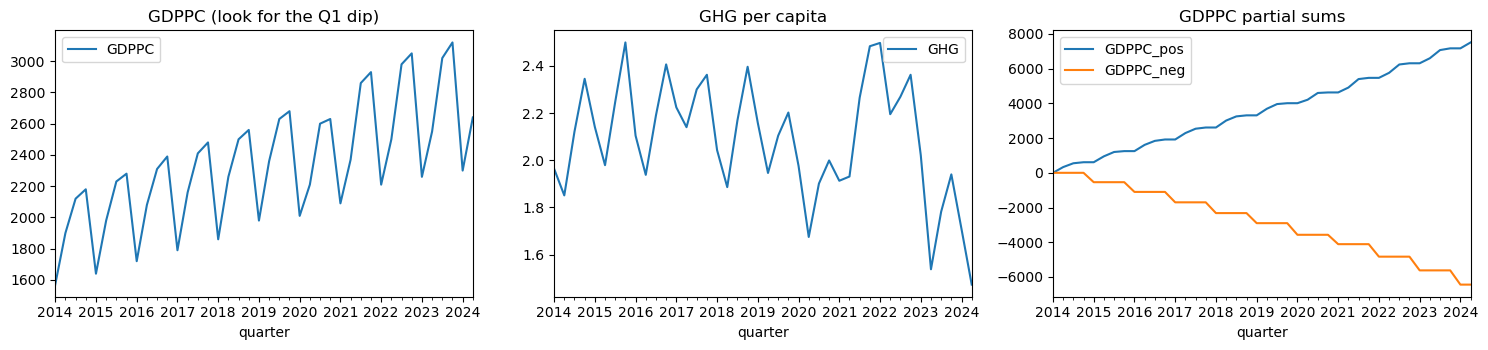

In [9]:
seas = seasonality_table(rep, ["GHG", "GDPPC", "MAN", "CON"])
TABLES["A2_seasonality"] = seas
display(seas.round(4))
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
rep[["GDPPC"]].plot(ax=ax[0], title="GDPPC (look for the Q1 dip)"); rep[["GHG"]].plot(ax=ax[1], title="GHG per capita")
rep[["GDPPC_pos", "GDPPC_neg"]].plot(ax=ax[2], title="GDPPC partial sums")
plt.tight_layout(); plt.show()

# Unit-root tests (ADF and PP, constant and constant+trend)

In [10]:
ur_cols = ["GHG", "MAN", "CON", "GDPPC", "MAN_pos", "MAN_neg", "GDPPC_pos", "GDPPC_neg"]
ur_rep = unit_root_table(rep, ur_cols)
TABLES["A3_unit_roots"] = ur_rep
display(ur_rep.round(4))
display(ur_rep[ur_rep["spec"] == "const"][["variable", "verdict"]].set_index("variable").T)

,variable,spec,ADF level p,ADF diff p,PP level p,PP diff p,verdict
0,GHG,const,0.0002,0.0190,0.0974,0.0,CONFLICT: inspect
1,GHG,const+trend,0.0001,0.0727,0.2760,0.0,CONFLICT: inspect
2,MAN,const,0.0000,0.0000,0.0000,0.0,I(0)
3,MAN,const+trend,0.0000,0.0000,0.0000,0.0,I(0)
4,CON,const,0.0022,0.0003,0.0000,0.0,I(0)
5,CON,const+trend,0.0021,0.0033,0.0000,0.0,I(0)
6,GDPPC,const,0.9118,0.0989,0.0001,0.0,CONFLICT: inspect
7,GDPPC,const+trend,0.0216,0.3124,0.0000,0.0,I(0)
8,MAN_pos,const,0.9991,0.4927,0.9991,0.0,CONFLICT: inspect
9,MAN_pos,const+trend,0.9956,0.0000,0.9742,0.0,I(1)


variable,GHG,MAN,CON,GDPPC,MAN_pos,MAN_neg,GDPPC_pos,GDPPC_neg
verdict,CONFLICT: inspect,I(0),I(0),CONFLICT: inspect,CONFLICT: inspect,I(1),CONFLICT: inspect,CONFLICT: inspect


###### Conflict means ADF and PP disagree. NARDL needs no I(2) variable

# The paper's exact specification

In [11]:
XV = ["MAN_pos", "MAN_neg", "GDPPC_pos", "GDPPC_neg", "CON"]
PAPER_Q = {"MAN_pos": 4, "MAN_neg": 1, "GDPPC_pos": 4, "GDPPC_neg": 4, "CON": 4}
m_paper = build_ecm(rep, "GHG", XV, p=2, q=PAPER_Q, fixed=["Dum"])
r = m_paper.res
print(f"Observations used: {int(r.nobs)}   regressors: {len(r.params)}   residual df: {int(r.df_resid)}   R2 = {r.rsquared:.3f}   adj. R2 = {r.rsquared_adj:.3f}")
if r.df_resid < 15:
    print("WARNING: very few residual degrees of freedom. Inference is fragile; treat significance stars with caution.")
est = pd.DataFrame({"coef": r.params, "se": r.bse, "t": r.tvalues, "p (t dist.)": r.pvalues})
est["sig"] = est["p (t dist.)"].apply(stars)
display(est.round(6))

Observations used: 38   regressors: 26   residual df: 12   R2 = 0.980   adj. R2 = 0.939


,coef,se,t,p (t dist.),sig
const,0.755328,0.307767,2.454219,0.030358,**
GHG_L1,-0.352901,0.131313,-2.687484,0.019762,**
MAN_pos_L1,-0.000200,0.000144,-1.390836,0.189528,
MAN_neg_L1,0.000024,0.000129,0.184235,0.856906,
GDPPC_pos_L1,-0.002600,0.000811,-3.204951,0.007563,***
GDPPC_neg_L1,-0.002974,0.000910,-3.269431,0.006710,***
CON_L1,-0.004167,0.001345,-3.097340,0.009236,***
dGHG_L1,0.207969,0.215336,0.965786,0.353212,
dMAN_pos_L0,-0.000088,0.000090,-0.977894,0.347430,
dMAN_pos_L1,-0.000025,0.000149,-0.166128,0.870822,


# Coefficients against the paper's Table 6

In [12]:
PAPER_T6 = {   # Zhelev et al. (2026), Table 6 (error-correction form)
    "GHG_L1": -0.527965, "MAN_pos_L1": -0.000270, "MAN_neg_L1": -1.32e-05,
    "GDPPC_neg_L1": -0.003439, "GDPPC_pos_L1": -0.003032, "CON_L1": -0.004036,
    "dGHG_L1": 0.344850,
    "dMAN_pos_L0": -3.34e-05, "dMAN_pos_L1": 0.000194, "dMAN_pos_L2": 0.000250, "dMAN_pos_L3": 0.000251,
    "dMAN_neg_L0": 0.000104,
    "dGDPPC_neg_L0": -0.001057, "dGDPPC_neg_L1": 0.001080, "dGDPPC_neg_L2": -0.000207, "dGDPPC_neg_L3": -0.000491,
    "dGDPPC_pos_L0": 0.001368, "dGDPPC_pos_L1": 0.003880, "dGDPPC_pos_L2": 0.003739, "dGDPPC_pos_L3": 0.002103,
    "dCON_L0": -0.000625, "dCON_L1": 0.002439, "dCON_L2": 0.001296, "dCON_L3": 0.000737,
    "Dum": 0.141706, "const": 0.726601,
}
cmp6 = pd.DataFrame({"paper": pd.Series(PAPER_T6), "ours": m_paper.res.params, "our p": m_paper.res.pvalues}).dropna(subset=["paper"])
cmp6["same sign"] = np.sign(cmp6["paper"]) == np.sign(cmp6["ours"])
TABLES["A5_table6_comparison"] = cmp6
display(cmp6.round(6))
print(f"Same sign on {int(cmp6['same sign'].sum())} of {len(cmp6)} coefficients")

,paper,ours,our p,same sign
CON_L1,-0.004036,-0.004167,0.009236,True
Dum,0.141706,0.090584,0.219427,True
GDPPC_neg_L1,-0.003439,-0.002974,0.006710,True
GDPPC_pos_L1,-0.003032,-0.002600,0.007563,True
GHG_L1,-0.527965,-0.352901,0.019762,True
MAN_neg_L1,-0.000013,0.000024,0.856906,False
MAN_pos_L1,-0.000270,-0.000200,0.189528,True
const,0.726601,0.755328,0.030358,True
dCON_L0,-0.000625,-0.000654,0.195479,True
dCON_L1,0.002439,0.003176,0.008110,True


Same sign on 23 of 26 coefficients


# Long-run effects, bounds test, symmetry tests and diagnostics against the paper

In [13]:
PAPER_LR = {"MAN_pos": -0.000511, "MAN_neg": -2.49e-05, "GDPPC_pos": -0.005743, "GDPPC_neg": -0.006513, "CON": -0.007645}
lr_rows = []
for x in XV:
    e = lr_effect(m_paper, {f"{x}_L1": 1})
    lr_rows.append(dict(variable=x, paper=PAPER_LR[x], ours=e["coef"], se=e["se"], p=e["p"], sig=stars(e["p"]), lo=e["lo"], hi=e["hi"]))
lr_tab = pd.DataFrame(lr_rows).set_index("variable")
TABLES["A6_long_run"] = lr_tab
display(lr_tab.round(6))
print("rho (error-correction term):", round(m_paper.res.params[m_paper.rho], 4), " paper: -0.5280")

,paper,ours,se,p,sig,lo,hi
variable,,,,,,,
MAN_pos,-0.000511,-0.000567,0.000467,0.247567,,-0.001584,0.000450
MAN_neg,-0.000025,0.000067,0.000357,0.853865,,-0.000710,0.000844
GDPPC_pos,-0.005743,-0.007369,0.004123,0.099171,*,-0.016352,0.001615
GDPPC_neg,-0.006513,-0.008426,0.004665,0.096012,*,-0.018591,0.001738
CON,-0.007645,-0.011809,0.005121,0.039755,**,-0.022966,-0.000652


rho (error-correction term): -0.3529  paper: -0.5280


In [14]:
bt = bounds_test(m_paper)

print("BOUNDS TEST (case III: unrestricted constant, no trend; small-sample critical values)")
print(f"  F statistic            : {bt['F']:.3f}   (paper: 6.69)")
print(f"  10% bounds I(0) / I(1) : {bt['I0_10']:.3f} / {bt['I1_10']:.3f}")
print(f"  5%  bounds I(0) / I(1) : {bt['I0_5']:.3f} / {bt['I1_5']:.3f}")
print(f"  1%  bounds I(0) / I(1) : {bt['I0_1']:.3f} / {bt['I1_1']:.3f}")
print("  Decision at 5%         :", bt["decision"])

if m_paper.res.params[m_paper.rho] >= 0:
    print(
        "  WARNING: the error-correction coefficient is not negative; "
        "there is no adjustment toward a long-run relation."
    )
    
wald_rows = [
    ("Wald LR symmetry MAN",   wald(m_paper.res, [{"MAN_pos_L1": 1, "MAN_neg_L1": -1}]), 13.489),
    ("Wald LR symmetry GDPPC", wald(m_paper.res, [{"GDPPC_pos_L1": 1, "GDPPC_neg_L1": -1}]), 18.416),
    ("Wald SR symmetry MAN",   wald(m_paper.res, [{**{c: 1 for c in m_paper.dnames("MAN_pos")}, **{c: -1 for c in m_paper.dnames("MAN_neg")}}]), 3.358),
    ("Wald SR symmetry GDPPC", wald(m_paper.res, [{**{c: 1 for c in m_paper.dnames("GDPPC_pos")}, **{c: -1 for c in m_paper.dnames("GDPPC_neg")}}]), 21.624),
]
wt = pd.DataFrame([dict(test=n, F=v[0], p=v[1], paper_F=pf) for n, v, pf in wald_rows]).set_index("test")
TABLES["A6_wald"] = wt
display(wt.round(4))

BOUNDS TEST (case III: unrestricted constant, no trend; small-sample critical values)
  F statistic            : 4.695   (paper: 6.69)
  10% bounds I(0) / I(1) : 2.510 / 3.752
  5%  bounds I(0) / I(1) : 3.054 / 4.452
  1%  bounds I(0) / I(1) : 4.430 / 6.062
  Decision at 5%         : cointegration (F above 5% upper bound)


,F,p,paper_F
test,,,
Wald LR symmetry MAN,6.2840,0.0276,13.489
Wald LR symmetry GDPPC,12.4676,0.0041,18.416
Wald SR symmetry MAN,0.7465,0.4045,3.358
Wald SR symmetry GDPPC,12.2812,0.0043,21.624


,ours,paper
Breusch-Godfrey LM,16.6840,NaN
BG p,0.0022,0.115
Breusch-Pagan LM,31.2327,NaN
BP p,0.1814,0.881
Jarque-Bera,0.7942,NaN
JB p,0.6723,0.193
RESET F,0.7483,NaN
RESET p,0.4055,0.558
CUSUM stat,0.2209,NaN
CUSUM p,1.0000,NaN


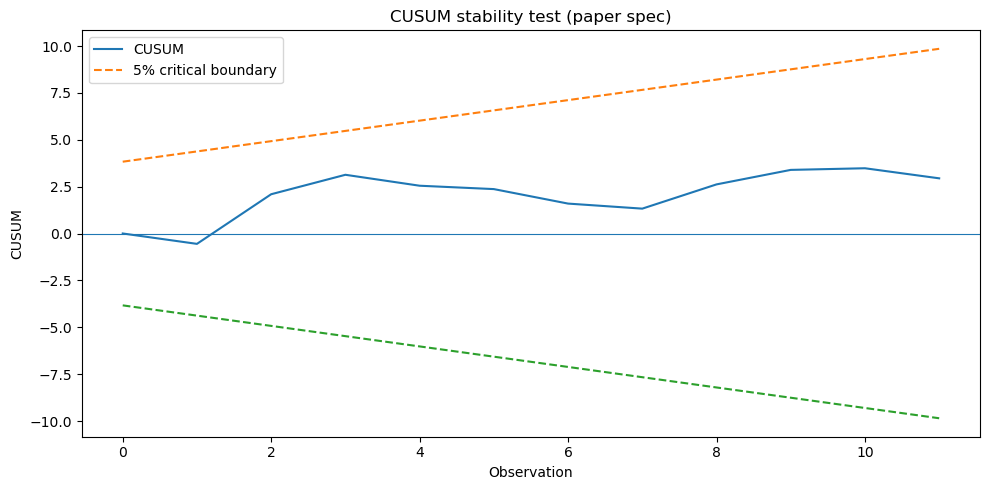

In [15]:
PAPER_DIAG = pd.Series({"BG p": 0.115, "BP p": 0.881, "JB p": 0.193, "RESET p": 0.558})
dg = diagnostics(m_paper)
dtab = pd.DataFrame({"ours": dg}); dtab["paper"] = PAPER_DIAG
TABLES["A6_diagnostics"] = dtab
display(dtab.round(4))
plot_stability(m_paper, "(paper spec)")

# Constrained lag search as a specification check

In [16]:
# Constrained lag search 
lag_rows = []
for p in (1, 2):
    for q_tuple in itertools.product((1, 2), repeat=len(XV)):
        q_dict = dict(zip(XV, q_tuple))
        try:
            m = build_ecm(rep, "GHG", XV, p=p, q=q_dict, fixed=["Dum"])
            b = bounds_test(m)
            dg = diagnostics(m)
            lag_rows.append({
                "p": p,
                "MAN_pos_q": q_dict["MAN_pos"],
                "MAN_neg_q": q_dict["MAN_neg"],
                "GDPPC_pos_q": q_dict["GDPPC_pos"],
                "GDPPC_neg_q": q_dict["GDPPC_neg"],
                "CON_q": q_dict["CON"],
                "AIC": m.res.aic,
                "BIC": m.res.bic,
                "rho": m.res.params[m.rho],
                "rho_p": m.res.pvalues[m.rho],
                "bounds_F": b["F"],
                "I0_5": b["I0_5"],
                "I1_5": b["I1_5"],
                "bounds_decision": b["decision"],
                "BG_p": dg["BG p"],
                "BP_p": dg["BP p"],
                "JB_p": dg["JB p"],
            })
        except Exception as e:
            pass

lag_check = pd.DataFrame(lag_rows).sort_values("BIC").reset_index(drop=True)
TABLES["A7_constrained_lag_search"] = lag_check
display(lag_check.head(10).round(4))

,p,MAN_pos_q,MAN_neg_q,GDPPC_pos_q,GDPPC_neg_q,CON_q,AIC,BIC,rho,rho_p,bounds_F,I0_5,I1_5,bounds_decision,BG_p,BP_p,JB_p
0,1,1,1,1,1,1,-67.4447,-45.1683,-0.3868,0.0004,20.1834,2.9649,4.3717,cointegration (F above 5% upper bound),0.1806,0.2211,0.7678
1,1,1,1,1,2,1,-68.5255,-44.8812,-0.2716,0.0307,2.3660,2.9808,4.3725,no cointegration (F below 5% lower bound),0.3905,0.0699,0.5464
2,1,1,1,1,2,2,-70.0083,-44.6751,-0.3080,0.0155,2.8539,2.9808,4.3725,no cointegration (F below 5% lower bound),0.3245,0.0563,0.4224
3,2,1,1,1,2,2,-71.6480,-44.6260,-0.3885,0.0055,3.0038,2.9808,4.3725,inconclusive (F between bounds),0.1862,0.0959,0.0316
4,2,1,1,1,2,1,-69.1155,-43.7823,-0.3393,0.0141,2.3705,2.9808,4.3725,no cointegration (F below 5% lower bound),0.3471,0.1421,0.2362
5,2,1,1,1,1,1,-67.0314,-43.3871,-0.4661,0.0002,19.2554,2.9808,4.3725,cointegration (F above 5% upper bound),0.1894,0.3766,0.8522
6,2,1,1,1,1,2,-68.4931,-43.1600,-0.5199,0.0001,19.4312,2.9808,4.3725,cointegration (F above 5% upper bound),0.0371,0.2864,0.4213
7,1,1,1,1,1,2,-66.6767,-43.0324,-0.4407,0.0002,20.5122,2.9808,4.3725,cointegration (F above 5% upper bound),0.0509,0.1732,0.6971
8,2,1,1,2,1,1,-67.4670,-42.1338,-0.4284,0.0006,7.0031,2.9808,4.3725,cointegration (F above 5% upper bound),0.3407,0.3420,0.7676
9,1,1,2,1,2,1,-67.0826,-41.7494,-0.2547,0.0502,2.3605,2.9808,4.3725,no cointegration (F below 5% lower bound),0.4685,0.0659,0.7609


# Replication summary

In [17]:
summary_lines = []
same = int(cmp6["same sign"].sum()); tot = len(cmp6)
summary_lines.append(f"Coefficients with the same sign as Table 6: {same}/{tot}.")
summary_lines.append(f"Error-correction term: {m_paper.res.params[m_paper.rho]:.3f} (paper -0.528).")
summary_lines.append(f"Bounds test: F = {bt['F']:.2f}; 5% bounds {bt['I0_5']:.2f}-{bt['I1_5']:.2f}; {bt['decision']}.")
summary_lines.append(f"Long-run MAN+: {lr_tab.loc['MAN_pos','ours']:.6f} (p = {lr_tab.loc['MAN_pos','p']:.3f}); paper {PAPER_LR['MAN_pos']:.6f}.")
summary_lines.append(f"LR symmetry MAN: p = {wt.loc['Wald LR symmetry MAN','p']:.3f}; GDPPC: p = {wt.loc['Wald LR symmetry GDPPC','p']:.3f}.")
print("\n".join(summary_lines))

Coefficients with the same sign as Table 6: 23/26.
Error-correction term: -0.353 (paper -0.528).
Bounds test: F = 4.69; 5% bounds 3.05-4.45; cointegration (F above 5% upper bound).
Long-run MAN+: -0.000567 (p = 0.248); paper -0.000511.
LR symmetry MAN: p = 0.028; GDPPC: p = 0.004.


# Sensitivity: how fragile is the replication?

In [18]:
def summ_rep(ecm, label):
    e_p, e_n = lr_effect(ecm, {"MAN_pos_L1": 1}), lr_effect(ecm, {"MAN_neg_L1": 1})
    b = bounds_test(ecm)
    dgx = diagnostics(ecm)
    return dict(variant=label, nobs=int(ecm.res.nobs), df_resid=int(ecm.res.df_resid), adjR2=ecm.res.rsquared_adj,
                rho=ecm.res.params[ecm.rho], F=b["F"], I1_5=b["I1_5"], bounds=b["decision"].split(" (")[0],
                LR_MANpos=e_p["coef"], p_MANpos=e_p["p"], LR_MANneg=e_n["coef"], p_MANneg=e_n["p"],
                p_symMAN=wald(ecm.res, [{"MAN_pos_L1": 1, "MAN_neg_L1": -1}])[1],
                p_symGDP=wald(ecm.res, [{"GDPPC_pos_L1": 1, "GDPPC_neg_L1": -1}])[1],
                BG_p=dgx["BG p"], JB_p=dgx["JB p"])

variants = []
variants.append(summ_rep(m_paper, "1. Paper spec + COVID dummy"))
variants.append(summ_rep(build_ecm(rep, "GHG", XV, 2, PAPER_Q, fixed=[]), "2. Paper spec, no dummy"))
variants.append(summ_rep(build_ecm(rep, "GHG", XV, 2, PAPER_Q, fixed=["Dum", "Q2", "Q3", "Q4"]), "3. + quarter dummies"))
rep_sa = make_nardl_frame(rep_raw, seasonal_adjust=True)
variants.append(summ_rep(build_ecm(rep_sa, "GHG", XV, 2, PAPER_Q, fixed=["Dum"]), "4. STL-adjusted GHG and GDPPC"))
grid = select_lags(rep, "GHG", XV, fixed=["Dum"], p_grid=(1, 2, 3), q_grid=(1, 2, 3, 4), common_q=False, min_df=10)
best = grid.iloc[0]
q_best = dict(zip(XV, best["q"]))
print("BIC-selected structure: p =", best["p"], " q =", q_best, f" (k = {best['k']}, n = {best['nobs']})")
variants.append(summ_rep(build_ecm(rep, "GHG", XV, int(best["p"]), q_best, fixed=["Dum"]), "5. BIC-selected lags"))
sens = pd.DataFrame(variants).set_index("variant")
TABLES["A8_sensitivity"] = sens
display(sens.round(4))

BIC-selected structure: p = 1  q = {'MAN_pos': 4, 'MAN_neg': 4, 'GDPPC_pos': 4, 'GDPPC_neg': 3, 'CON': 3}  (k = 26, n = 38)


,nobs,df_resid,adjR2,rho,F,I1_5,bounds,LR_MANpos,p_MANpos,LR_MANneg,p_MANneg,p_symMAN,p_symGDP,BG_p,JB_p
variant,,,,,,,,,,,,,,,
1. Paper spec + COVID dummy,38,12,0.9389,-0.3529,4.6947,4.4515,cointegration,-0.0006,0.2476,0.0001,0.8539,0.0276,0.0041,0.0022,0.6723
"2. Paper spec, no dummy",38,13,0.9358,-0.3864,4.2464,4.4515,inconclusive,-0.0005,0.2694,0.0001,0.7076,0.0227,0.0069,0.0044,0.5631
3. + quarter dummies,38,9,0.9481,-0.3005,5.2763,4.4515,cointegration,-0.0008,0.2065,-0.0000,0.9166,0.0247,0.0031,0.0117,0.5747
4. STL-adjusted GHG and GDPPC,38,12,0.7175,-0.7215,5.6465,4.4515,cointegration,-0.0007,0.0255,-0.0001,0.5558,0.0036,0.0047,0.0961,0.6455
5. BIC-selected lags,38,12,0.9567,-0.2356,11.7856,4.4515,cointegration,0.0011,0.2571,0.0031,0.0596,0.0007,0.0001,0.0805,0.3249


# EXTENSION 2014 - 2025


#  Data

In [19]:
ext_raw = read_quarterly(EXTENSION_FILE, "time")[["GHG", "MAN", "CON", "GDPPC"]]
check_continuity(ext_raw.loc[EXT_START:EXT_END], "Extension data")

eua = pd.read_csv(CARBON_FILE)
eua["date"] = pd.to_datetime(eua["date"], errors="coerce")
eua["EUA_price"] = pd.to_numeric(eua["EUA_price"], errors="coerce")
eua = eua.dropna(subset=["date", "EUA_price"]).sort_values("date")
eua["quarter"] = eua["date"].dt.to_period("Q")
cp_q = pd.DataFrame({
    "CP_mean": eua.groupby("quarter")["EUA_price"].mean(),
    "CP_last": eua.groupby("quarter")["EUA_price"].last(),
    "n_obs":   eua.groupby("quarter")["EUA_price"].size(),
}).loc[EXT_START:EXT_END]
display(cp_q.describe().round(2))
print("Source file names (to confirm what the prices are):", eua["source_file"].str[:45].unique()[:3])

Extension data: 48 quarters, 2014Q1 to 2025Q4, continuous: True


,CP_mean,CP_last,n_obs
count,48.00,48.00,48.00
mean,37.01,37.33,53.23
std,30.82,30.75,4.77
min,4.52,4.17,43.00
25%,7.20,7.08,50.75
50%,24.91,25.51,53.00
75%,67.98,66.57,56.00
max,87.50,88.61,66.00


Source file names (to confirm what the prices are): ['emission-spot-primary-market-auction-report-2']


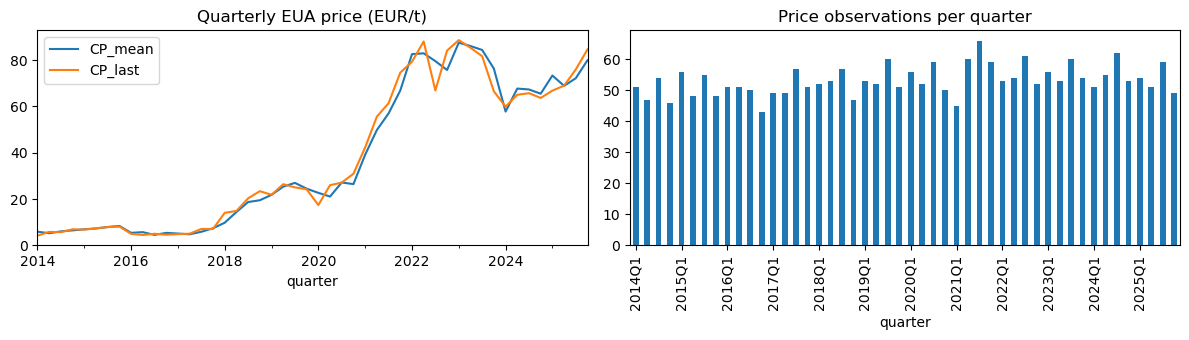

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
cp_q[["CP_mean", "CP_last"]].plot(ax=ax[0], title="Quarterly EUA price (EUR/t)")
cp_q["n_obs"].plot(kind="bar", ax=ax[1], title="Price observations per quarter"); ax[1].set_xticks(ax[1].get_xticks()[::4])
plt.tight_layout(); plt.show()

In [21]:
def make_ext_frame(raw, cp, start=EXT_START, end=EXT_END, seasonal_adjust=False, cp_col="CP_mean"):
    d = make_nardl_frame(raw.loc[start:end], seasonal_adjust)
    for c in ["MAN_pos", "MAN_neg", "CON", "GDPPC_pos", "GDPPC_neg"]:
        d[c] = d[c] / 1000.0                       # EUR million -> billion ; EUR -> thousand EUR
    d = d.join(cp[[cp_col]].rename(columns={cp_col: "CP_raw"}))
    if d["CP_raw"].isna().any():
        raise ValueError(f"Carbon price missing for: {list(d.index[d['CP_raw'].isna()])}")
    cp_mean = float(d["CP_raw"].mean())
    d["CP"] = d["CP_raw"] - cp_mean                # centred
    d["MAN_pos_CP"] = d["MAN_pos"] * d["CP"]
    d["MAN_neg_CP"] = d["MAN_neg"] * d["CP"]
    return d, cp_mean

ext, CP_MEAN = make_ext_frame(ext_raw, cp_q)
print(f"{len(ext)} quarters, mean carbon price = EUR {CP_MEAN:.2f}/t, range {ext['CP_raw'].min():.1f} to {ext['CP_raw'].max():.1f}")
display(ext[["GHG", "MAN_pos", "MAN_neg", "GDPPC_pos", "GDPPC_neg", "CON", "CP_raw", "CP", "MAN_pos_CP", "MAN_neg_CP"]].tail(6).round(3))

48 quarters, mean carbon price = EUR 37.01/t, range 4.5 to 87.5


,GHG,MAN_pos,MAN_neg,GDPPC_pos,GDPPC_neg,CON,CP_raw,CP,MAN_pos_CP,MAN_neg_CP
time,,,,,,,,,,
2024Q3,1.877,4.795,-4.557,8.00,-6.44,0.024,67.303,30.291,145.235,-138.035
2024Q4,2.112,4.795,-4.959,8.13,-6.44,-0.025,65.468,28.456,136.437,-141.124
2025Q1,2.159,5.112,-4.959,8.13,-7.33,0.033,73.329,36.317,185.645,-180.110
2025Q2,1.567,5.112,-5.056,8.50,-7.33,0.039,68.859,31.847,162.793,-161.019
2025Q3,1.798,5.289,-5.056,8.99,-7.33,0.044,72.159,35.146,185.888,-177.702
2025Q4,2.039,5.289,-5.148,9.14,-7.33,-0.058,79.927,42.914,226.974,-220.941


# Data checks: seasonality, unit roots, collinearity

In [22]:
display(seasonality_table(ext, ["GHG", "GDPPC", "MAN", "CON"]).round(4))
ur_ext = unit_root_table(ext, ["GHG", "MAN_pos", "MAN_neg", "GDPPC_pos", "GDPPC_neg", "CON", "CP", "MAN_pos_CP", "MAN_neg_CP"])
TABLES["B2_unit_roots"] = ur_ext
display(ur_ext[ur_ext["spec"] == "const"].round(4))
print("Correlation of MAN_pos and MAN_neg:", round(ext["MAN_pos"].corr(ext["MAN_neg"]), 3),
      "| MAN_pos_CP and MAN_neg_CP:", round(ext["MAN_pos_CP"].corr(ext["MAN_neg_CP"]), 3))

,R2 of quarter dummies,F p-value,mean Q1,mean Q2,mean Q3,mean Q4
variable,,,,,,
GHG,0.3673,0.0001,2.0757,1.8432,2.0852,2.2621
GDPPC,0.4807,0.0000,1983.3333,2312.5000,2668.3333,2745.0000
MAN,0.1816,0.0304,145.0500,160.9667,81.1083,-59.6000
CON,0.0580,0.4475,0.0106,0.0258,0.0244,0.0053


,variable,spec,ADF level p,ADF diff p,PP level p,PP diff p,verdict
0,GHG,const,0.0041,0.0117,0.0042,0.0,I(0)
2,MAN_pos,const,0.9978,0.3742,0.9955,0.0,CONFLICT: inspect
4,MAN_neg,const,0.9964,0.0000,0.9974,0.0,I(1)
6,GDPPC_pos,const,0.9988,0.9581,0.9990,0.0,CONFLICT: inspect
8,GDPPC_neg,const,0.9988,0.9217,0.9948,0.0,CONFLICT: inspect
10,CON,const,0.0000,0.0000,0.0000,0.0,I(0)
12,CP,const,0.9307,0.0000,0.9080,0.0,I(1)
14,MAN_pos_CP,const,0.9661,0.0000,0.9768,0.0,I(1)
16,MAN_neg_CP,const,0.9844,0.3957,0.9865,0.0,CONFLICT: inspect


Correlation of MAN_pos and MAN_neg: -0.992 | MAN_pos_CP and MAN_neg_CP: -0.996


# Lag structure (common sample, common q for all regressors)

In [23]:
XV0 = ["MAN_pos", "MAN_neg", "GDPPC_pos", "GDPPC_neg", "CON"]
XV1 = XV0 + ["CP"]
XV2 = XV1 + ["MAN_pos_CP", "MAN_neg_CP"]
FIXED = ["Dum"]

lag_grid = select_lags(ext, "GHG", XV2, fixed=FIXED, p_grid=(1, 2, 3), q_grid=(1, 2, 3), common_q=True, min_df=15)
TABLES["B3_lag_selection"] = lag_grid.assign(q=lag_grid["q"].apply(lambda t: t[0]))
display(lag_grid.assign(q=lag_grid["q"].apply(lambda t: t[0])).round(3))
P_SEL = int(lag_grid.iloc[0]["p"]); Q_SEL = int(lag_grid.iloc[0]["q"][0])
print(f"Selected by BIC (M2 on a common sample): p = {P_SEL}, q = {Q_SEL} for every regressor")

,p,q,k,nobs,bic,aic
0,2,1,20,45,-165.826,-201.960
1,1,2,27,45,-165.766,-214.546
2,2,2,28,45,-164.269,-214.855
3,1,1,19,45,-163.657,-197.983
4,3,1,21,45,-162.704,-200.644
5,3,2,29,45,-161.616,-214.009


Selected by BIC (M2 on a common sample): p = 2, q = 1 for every regressor


# Estimate M0, M1, M2 and compare

In [24]:
models = {
    "M0 baseline NARDL":       build_ecm(ext, "GHG", XV0, P_SEL, Q_SEL, fixed=FIXED),
    "M1 + carbon price":       build_ecm(ext, "GHG", XV1, P_SEL, Q_SEL, fixed=FIXED),
    "M2 + CP x MAN interact.": build_ecm(ext, "GHG", XV2, P_SEL, Q_SEL, fixed=FIXED),
}
rows = []
for name, m in models.items():
    b = bounds_test(m)
    rows.append(dict(model=name, nobs=int(m.res.nobs), k=len(m.res.params), df_resid=int(m.res.df_resid),
                     adjR2=m.res.rsquared_adj, AIC=m.res.aic, BIC=m.res.bic, rho=m.res.params[m.rho],
                     F_bounds=b["F"], I0_5=b["I0_5"], I1_5=b["I1_5"], bounds=b["decision"].split(" (")[0]))
cmp_models = pd.DataFrame(rows).set_index("model")
for n_, m_ in models.items():
    if m_.res.df_resid < 10:
        print(f"WARNING: {n_} has only {int(m_.res.df_resid)} residual df; treat its inference as fragile.")
TABLES["B4_model_comparison"] = cmp_models
display(cmp_models.round(4))

m1, m2 = models["M1 + carbon price"], models["M2 + CP x MAN interact."]
f_c, p_c, df_c = m2.res.compare_f_test(m1.res)
print(f"Does the interaction block improve on M1?  F = {f_c:.3f}, p = {p_c:.4f}, extra terms = {int(df_c)}")
f_c0, p_c0, df_c0 = m1.res.compare_f_test(models["M0 baseline NARDL"].res)
print(f"Does adding CP improve on M0?              F = {f_c0:.3f}, p = {p_c0:.4f}, extra terms = {int(df_c0)}")

,nobs,k,df_resid,adjR2,AIC,BIC,rho,F_bounds,I0_5,I1_5,bounds
model,,,,,,,,,,,
M0 baseline NARDL,46,14,32,0.8309,-67.9298,-42.3288,-0.5434,27.3956,2.9236,4.2453,cointegration
M1 + carbon price,46,16,30,0.8688,-78.5606,-49.3023,-0.5402,29.8371,2.7518,4.0152,cointegration
M2 + CP x MAN interact.,46,20,26,0.8704,-77.7043,-41.1315,-0.5792,20.2314,2.5011,3.9090,cointegration


Does the interaction block improve on M1?  F = 1.092, p = 0.3811, extra terms = 4
Does adding CP improve on M0?              F = 5.617, p = 0.0085, extra terms = 2


# Long-run effects in M2

In [25]:
m = m2
lr_rows = []
for x in XV2:
    e = lr_effect(m, {f"{x}_L1": 1})
    lr_rows.append(dict(variable=x, long_run=e["coef"], se=e["se"], p=e["p"], sig=stars(e["p"]), ci_low=e["lo"], ci_high=e["hi"]))
lr2 = pd.DataFrame(lr_rows).set_index("variable")
TABLES["B5_long_run_M2"] = lr2
display(lr2.round(5))
print("rho =", round(m.res.params[m.rho], 4), "(must be negative and, for cointegration, significantly so)")
if m.res.params[m.rho] >= 0:
    print("WARNING: rho >= 0, so the long-run effects below are not meaningful.")

,long_run,se,p,sig,ci_low,ci_high
variable,,,,,,
MAN_pos,-0.41199,0.34901,0.24851,,-1.12939,0.30542
MAN_neg,-0.25192,0.33462,0.45830,,-0.93974,0.43590
GDPPC_pos,1.38078,0.37860,0.00117,***,0.60255,2.15901
GDPPC_neg,1.58438,0.48207,0.00290,***,0.59348,2.57528
CON,-0.33275,1.26577,0.79471,,-2.93457,2.26907
CP,0.00164,0.00688,0.81330,,-0.01250,0.01579
MAN_pos_CP,-0.00593,0.00696,0.40203,,-0.02025,0.00838
MAN_neg_CP,-0.00721,0.00789,0.36901,,-0.02343,0.00901


rho = -0.5792 (must be negative and, for cointegration, significantly so)


# Long-run effects in M0

In [26]:
m0 = models["M0 baseline NARDL"]

lr_rows_m0 = []

for x in XV0:
    e = lr_effect(m0, {f"{x}_L1": 1})
    lr_rows_m0.append({
        "variable": x,
        "long_run": e["coef"],
        "se": e["se"],
        "p": e["p"],
        "sig": stars(e["p"]),
        "ci_low": e["lo"],
        "ci_high": e["hi"]
    })

lr0 = pd.DataFrame(lr_rows_m0).set_index("variable")

TABLES["B5a_long_run_M0"] = lr0

display(lr0.round(5))

print("M0 rho =", round(m0.res.params[m0.rho], 4))

,long_run,se,p,sig,ci_low,ci_high
variable,,,,,,
MAN_pos,-0.33312,0.29342,0.26468,,-0.93080,0.26455
MAN_neg,-0.18603,0.28899,0.52434,,-0.77468,0.40262
GDPPC_pos,1.72380,0.41502,0.00023,***,0.87843,2.56918
GDPPC_neg,1.93690,0.47481,0.00028,***,0.96974,2.90407
CON,-0.88702,1.31690,0.50542,,-3.56945,1.79541


M0 rho = -0.5434


# Positive-shock-only carbon-price moderation

In [27]:
XV3 = XV1 + ["MAN_pos_CP"]

m3 = build_ecm(
    ext,
    "GHG",
    XV3,
    P_SEL,
    Q_SEL,
    fixed=FIXED
)

b3 = bounds_test(m3)
dg3 = diagnostics(m3)

print("M3: positive-shock-only moderation")
print(f"Observations = {int(m3.res.nobs)}")
print(f"Residual df = {int(m3.res.df_resid)}")
print(f"R2 = {m3.res.rsquared:.4f}")
print(f"Adjusted R2 = {m3.res.rsquared_adj:.4f}")
print(f"rho = {m3.res.params[m3.rho]:.6f}")
print(f"rho p-value = {m3.res.pvalues[m3.rho]:.4f}")
print(f"Bounds F = {b3['F']:.4f}")
print(f"Bounds decision = {b3['decision']}")

# compare M3 with M1
f_m3, p_m3, df_m3 = m3.res.compare_f_test(m1.res)

print(
    f"Does MAN+ × CP improve on M1? "
    f"F = {f_m3:.3f}, p = {p_m3:.4f}, extra terms = {int(df_m3)}"
)

M3: positive-shock-only moderation
Observations = 46
Residual df = 28
R2 = 0.9187
Adjusted R2 = 0.8694
rho = -0.580128
rho p-value = 0.0000
Bounds F = 25.5794
Bounds decision = cointegration (F above 5% upper bound)
Does MAN+ × CP improve on M1? F = 1.067, p = 0.3575, extra terms = 2


# Long run effects in M3

In [28]:
lr_rows_m3 = []

for x in XV3:
    e = lr_effect(m3, {f"{x}_L1": 1})
    lr_rows_m3.append({
        "variable": x,
        "long_run": e["coef"],
        "se": e["se"],
        "p": e["p"],
        "sig": stars(e["p"]),
        "ci_low": e["lo"],
        "ci_high": e["hi"]
    })

lr3 = pd.DataFrame(lr_rows_m3).set_index("variable")

TABLES["B10_long_run_M3"] = lr3

display(lr3.round(5))

e3_pos = lr_effect(
    m3,
    {"MAN_pos_CP_L1": 1}
)

print(
    f"LR MAN+ × CP = {e3_pos['coef']:.5f} "
    f"(SE = {e3_pos['se']:.5f}, p = {e3_pos['p']:.4f})"
)

print(
    f"One-sided p-value for a negative moderation effect = "
    f"{one_sided_p(e3_pos['coef'], e3_pos['p'], '<'):.4f}"
)

,long_run,se,p,sig,ci_low,ci_high
variable,,,,,,
MAN_pos,-0.56011,0.34178,0.11245,,-1.26022,0.14001
MAN_neg,-0.48829,0.28149,0.09380,*,-1.06489,0.08832
GDPPC_pos,1.39179,0.37286,0.00086,***,0.62802,2.15556
GDPPC_neg,1.64905,0.45883,0.00123,***,0.70917,2.58893
CON,0.13278,1.23027,0.91482,,-2.38732,2.65288
CP,0.00406,0.00657,0.54126,,-0.00940,0.01753
MAN_pos_CP,-0.00014,0.00243,0.95313,,-0.00512,0.00483


LR MAN+ × CP = -0.00014 (SE = 0.00243, p = 0.9531)
One-sided p-value for a negative moderation effect = 0.4766


# Moderation model with a linear time trend

In [29]:
# add a deterministic linear time trend
ext["Trend"] = np.arange(1, len(ext) + 1)

# M4: full moderation model with a linear time trend

m4 = build_ecm(
    ext,
    "GHG",
    XV2,
    P_SEL,
    Q_SEL,
    fixed=["Dum", "Trend"]
)

b4 = bounds_test(m4)
dg4 = diagnostics(m4)

print("M4: full moderation model + linear time trend")
print(f"Observations = {int(m4.res.nobs)}")
print(f"Residual df = {int(m4.res.df_resid)}")
print(f"R2 = {m4.res.rsquared:.4f}")
print(f"Adjusted R2 = {m4.res.rsquared_adj:.4f}")
print(f"rho = {m4.res.params[m4.rho]:.6f}")
print(f"rho p-value = {m4.res.pvalues[m4.rho]:.4f}")
print(f"Bounds F = {b4['F']:.4f}")
print(f"Bounds decision = {b4['decision']}")

M4: full moderation model + linear time trend
Observations = 46
Residual df = 25
R2 = 0.9259
Adjusted R2 = 0.8666
rho = -0.577292
rho p-value = 0.0000
Bounds F = 19.6496
Bounds decision = cointegration (F above 5% upper bound)


# Long run effects in M4

In [30]:
lr_rows_m4 = []

for x in XV2:
    e = lr_effect(m4, {f"{x}_L1": 1})
    lr_rows_m4.append({
        "variable": x,
        "long_run": e["coef"],
        "se": e["se"],
        "p": e["p"],
        "sig": stars(e["p"]),
        "ci_low": e["lo"],
        "ci_high": e["hi"]
    })

lr4 = pd.DataFrame(lr_rows_m4).set_index("variable")

TABLES["B11_long_run_M4"] = lr4

display(lr4.round(5))

,long_run,se,p,sig,ci_low,ci_high
variable,,,,,,
MAN_pos,-0.48910,0.38893,0.22018,,-1.29012,0.31192
MAN_neg,-0.30051,0.35762,0.40870,,-1.03705,0.43603
GDPPC_pos,1.23784,0.45775,0.01214,**,0.29509,2.18058
GDPPC_neg,1.68546,0.54515,0.00484,***,0.56271,2.80822
CON,-0.45705,1.31043,0.73017,,-3.15594,2.24183
CP,-0.00337,0.01211,0.78333,,-0.02831,0.02158
MAN_pos_CP,-0.00531,0.00720,0.46769,,-0.02014,0.00952
MAN_neg_CP,-0.00841,0.00836,0.32367,,-0.02562,0.00880


In [31]:
# Carbon-price moderation after controlling for a linear trend

e4_pos = lr_effect(
    m4,
    {"MAN_pos_CP_L1": 1}
)

e4_neg = lr_effect(
    m4,
    {"MAN_neg_CP_L1": 1}
)

print(
    f"LR MAN+ × CP = {e4_pos['coef']:.5f} "
    f"(SE = {e4_pos['se']:.5f}, p = {e4_pos['p']:.4f})"
)

print(
    f"One-sided p-value for negative MAN+ × CP = "
    f"{one_sided_p(e4_pos['coef'], e4_pos['p'], '<'):.4f}"
)

print(
    f"LR MAN- × CP = {e4_neg['coef']:.5f} "
    f"(SE = {e4_neg['se']:.5f}, p = {e4_neg['p']:.4f})"
)

print("\nDiagnostics")
print(f"BG p = {dg4['BG p']:.4f}")
print(f"BP p = {dg4['BP p']:.4f}")
print(f"JB p = {dg4['JB p']:.4f}")
print(f"RESET p = {dg4['RESET p']:.4f}")

LR MAN+ × CP = -0.00531 (SE = 0.00720, p = 0.4677)
One-sided p-value for negative MAN+ × CP = 0.2338
LR MAN- × CP = -0.00841 (SE = 0.00836, p = 0.3237)

Diagnostics
BG p = 0.0073
BP p = 0.1978
JB p = 0.3761
RESET p = 0.7597


# Short-run effects in M2

In [32]:
sr_rows = []

for name in m2.res.params.index:
    if name.startswith("d"):
        sr_rows.append({
            "variable": name,
            "coef": m2.res.params[name],
            "se": m2.res.bse[name],
            "t": m2.res.tvalues[name],
            "p": m2.res.pvalues[name],
            "sig": stars(m2.res.pvalues[name])
        })

sr2 = pd.DataFrame(sr_rows).set_index("variable")

TABLES["B5b_short_run_M2"] = sr2

display(sr2.round(6))

,coef,se,t,p,sig
variable,,,,,
dGHG_L1,0.291319,0.152258,1.913321,0.066779,*
dMAN_pos_L0,-0.140898,0.176192,-0.799680,0.431142,
dMAN_neg_L0,-0.112769,0.151781,-0.742974,0.464158,
dGDPPC_pos_L0,1.079416,0.248054,4.351526,0.000186,***
dGDPPC_neg_L0,0.396723,0.107304,3.697192,0.001025,***
dCON_L0,0.732019,0.481267,1.521023,0.140324,
dCP_L0,0.000439,0.013460,0.032643,0.974209,
dMAN_pos_CP_L0,0.003080,0.003038,1.013764,0.320037,
dMAN_neg_CP_L0,0.000408,0.003290,0.124013,0.902259,


In [33]:
# fixed variables in M2

fixed_rows = []

for name in m2.fixed:
    if name in m2.res.params.index:
        fixed_rows.append({
            "variable": name,
            "coef": m2.res.params[name],
            "se": m2.res.bse[name],
            "t": m2.res.tvalues[name],
            "p": m2.res.pvalues[name],
            "sig": stars(m2.res.pvalues[name])
        })

fixed2 = pd.DataFrame(fixed_rows).set_index("variable")

if not fixed2.empty:
    print("\nFixed variables")
    display(fixed2.round(6))


Fixed variables


,coef,se,t,p,sig
variable,,,,,
Dum,0.007166,0.089707,0.079877,0.936947,


# The hypotheses

### H1: Manufacturing FDI increases emissions in the short run

An increase in manufacturing FDI is expected to increase GHG emissions in the short run, consistent with the pollution haven effect.

The hypothesis is supported if the sum of the short-run coefficients on positive changes in manufacturing FDI is positive:

$$
H_1: \sum \delta_{MAN^+} > 0
$$

where $\delta_{MAN^+}$ represents the short-run coefficients associated with $\Delta MAN^+$ and its relevant lags.

---

### H2: Higher carbon prices weaken the short-run emission-increasing effect of manufacturing FDI

A higher carbon price is expected to reduce the extent to which an increase in manufacturing FDI raises GHG emissions. Therefore, as carbon prices increase, the short-run emission-increasing effect of manufacturing FDI should become weaker.

The hypothesis is supported if the sum of the short-run coefficients on the interaction between positive manufacturing FDI and the carbon price is negative:

$$
H_2: \sum \delta_{MAN^+ \times CP} < 0
$$

where $\delta_{MAN^+ \times CP}$ represents the short-run coefficients associated with the interaction between positive manufacturing FDI and the carbon price.

---

### H3: Higher carbon prices strengthen the long-run emission-reducing effect of manufacturing FDI

In the long run, higher carbon prices are expected to strengthen the environmental benefits associated with manufacturing FDI. Therefore, as carbon prices increase, the long-run effect of positive manufacturing FDI on GHG emissions should become more negative.

The hypothesis is supported if the long-run coefficient on the interaction between positive manufacturing FDI and the carbon price is negative:

$$
H_3: \beta_{MAN^+ \times CP}^{LR} < 0
$$

where $\beta_{MAN^+ \times CP}^{LR}$ represents the long-run coefficient on the interaction between positive manufacturing FDI and the carbon price.

In [34]:
def hyp_row(label, est, se, p_two, direction, note=""):
    p1 = one_sided_p(est, p_two, direction)
    return dict(
        hypothesis=label,
        estimate=est,
        se=se,
        p_two_sided=p_two,
        direction=direction,
        p_one_sided=p1,
        supported_10pct="yes" if p1 < 0.10 else "no",
        note=note
    )

# short-run effects evaluated at the mean carbon price
cp_mean = ext["CP"].mean()

sr_man = {
    c: 1
    for c in m2.dnames("MAN_pos")
}

sr_man_cp = {
    c: 1
    for c in m2.dnames("MAN_pos_CP")
}

e_man = lin_comb(m2.res, sr_man)
e_man_cp = lin_comb(m2.res, sr_man_cp)

# marginal short-run effect of MAN+ at the mean carbon price
e1 = lin_comb(
    m2.res,
    {
        **sr_man,
        **{k: cp_mean * v for k, v in sr_man_cp.items()}
    }
)

# effect of carbon price on the short-run MAN+ relationship
e2 = e_man_cp

# long-run moderation effect
e3 = lr_effect(
    m2,
    {"MAN_pos_CP_L1": 1}
)

hyp = pd.DataFrame([
    hyp_row(
        "H1: MAN+ increases GHG emissions in the short run",
        e1[0],
        e1[1],
        e1[3],
        ">",
        f"marginal effect evaluated at mean carbon price ({cp_mean:.2f})"
    ),
    hyp_row(
        "H2: carbon price weakens the short-run MAN+ effect",
        e2[0],
        e2[1],
        e2[3],
        "<"
    ),
    hyp_row(
        "H3: carbon price strengthens the long-run emission-reducing effect of MAN+",
        e3["coef"],
        e3["se"],
        e3["p"],
        "<"
    )
]).set_index("hypothesis")

TABLES["B6_hypotheses"] = hyp

display(hyp.round(4))

# additional long-run moderation results
e4 = lr_effect(
    m2,
    {"MAN_neg_CP_L1": 1}
)

jt = wald(
    m2.res,
    [
        {"MAN_pos_CP_L1": 1},
        {"MAN_neg_CP_L1": 1}
    ]
)

sym = wald(
    m2.res,
    [
        {
            "MAN_pos_CP_L1": 1,
            "MAN_neg_CP_L1": -1
        }
    ]
)

print(f"Mean carbon price = {cp_mean:.4f}")
print(f"LR MAN+ × CP = {e3['coef']:.5f} (p = {e3['p']:.3f})")
print(f"LR MAN- × CP = {e4['coef']:.5f} (p = {e4['p']:.3f})")
print(f"Joint test, both long-run interaction coefficients = 0: F = {jt[0]:.3f}, p = {jt[1]:.4f}")
print(f"Symmetric moderation (MAN+ × CP = MAN- × CP): F = {sym[0]:.3f}, p = {sym[1]:.4f}")

,estimate,se,p_two_sided,direction,p_one_sided,supported_10pct,note
hypothesis,,,,,,,
H1: MAN+ increases GHG emissions in the short run,-0.1409,0.1762,0.4311,>,0.7844,no,marginal effect evaluated at mean carbon price...
H2: carbon price weakens the short-run MAN+ effect,0.0031,0.0030,0.3200,<,0.8400,no,
H3: carbon price strengthens the long-run emission-reducing effect of MAN+,-0.0059,0.0070,0.4020,<,0.2010,no,


Mean carbon price = -0.0000
LR MAN+ × CP = -0.00593 (p = 0.402)
LR MAN- × CP = -0.00721 (p = 0.369)
Joint test, both long-run interaction coefficients = 0: F = 0.396, p = 0.6770
Symmetric moderation (MAN+ × CP = MAN- × CP): F = 0.208, p = 0.6525


In [35]:
rho = m2.res.params[m2.rho]
rho_p = m2.res.pvalues[m2.rho]

print(f"Error-correction coefficient: {rho:.6f}")
print(f"p-value: {rho_p:.4f}")

if rho < 0 and rho_p < 0.05:
    print("The error-correction term is negative and statistically significant,")
    print("indicating adjustment toward the long-run equilibrium.")
else:
    print("The error-correction term does not provide strong evidence of")
    print("adjustment toward the long-run equilibrium.")

Error-correction coefficient: -0.579210
p-value: 0.0000
The error-correction term is negative and statistically significant,
indicating adjustment toward the long-run equilibrium.


# Marginal effect of manufacturing FDI at different carbon prices

Long-run effect of a positive manufacturing-FDI shock on GHG per capita, by carbon price (EUR/t):


,effect,se,p,sig,ci_low,ci_high
carbon_price,,,,,,
4.516400,-0.21917,0.47083,0.64545,,-1.18698,0.74864
7.197879,-0.23508,0.45778,0.61192,,-1.17607,0.70590
24.907374,-0.34016,0.38346,0.38316,,-1.12837,0.44805
67.982664,-0.59575,0.34924,0.09996,*,-1.31362,0.12212
87.496964,-0.71153,0.41213,0.09613,*,-1.55869,0.13562


Long-run effect of a negative manufacturing-FDI shock:


,effect,se,p,sig,ci_low,ci_high
carbon_price,,,,,,
4.516400,-0.01750,0.52243,0.97354,,-1.09137,1.05637
7.197879,-0.03684,0.50465,0.94236,,-1.07416,1.00048
24.907374,-0.16460,0.39568,0.68084,,-0.97792,0.64873
67.982664,-0.47534,0.28453,0.10679,,-1.06019,0.10952
87.496964,-0.61611,0.35037,0.09043,*,-1.33630,0.10408


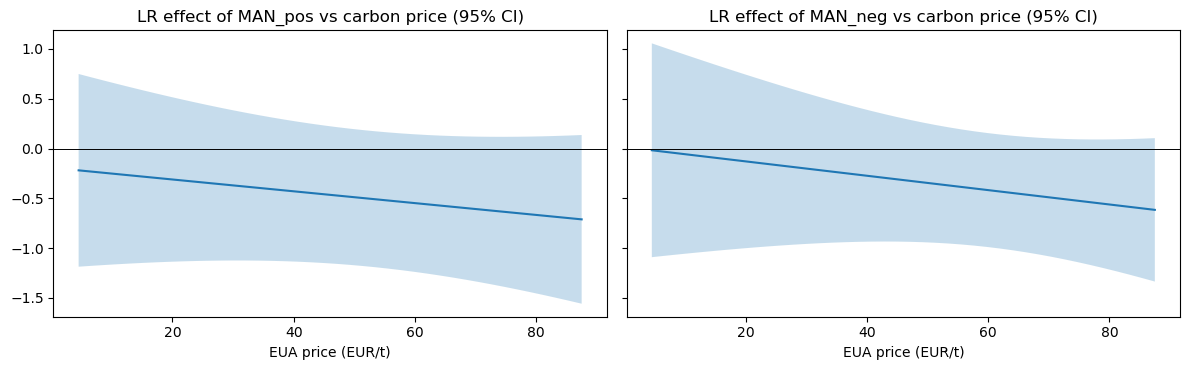

In [36]:
def marginal_effects(model, shock="MAN_pos", prices=None):
    prices = prices if prices is not None else ext["CP_raw"].quantile([0, .25, .5, .75, 1]).values
    rows = []
    for P in prices:
        e = lr_effect(model, {f"{shock}_L1": 1, f"{shock}_CP_L1": P - CP_MEAN})
        rows.append(dict(carbon_price=P, effect=e["coef"], se=e["se"], p=e["p"], sig=stars(e["p"]), ci_low=e["lo"], ci_high=e["hi"]))
    return pd.DataFrame(rows).set_index("carbon_price")

me_pos = marginal_effects(m2, "MAN_pos")
me_neg = marginal_effects(m2, "MAN_neg")
TABLES["B7_marginal_MANpos"] = me_pos; TABLES["B7_marginal_MANneg"] = me_neg
print("Long-run effect of a positive manufacturing-FDI shock on GHG per capita, by carbon price (EUR/t):")
display(me_pos.round(5))
print("Long-run effect of a negative manufacturing-FDI shock:")
display(me_neg.round(5))

grid = np.linspace(ext["CP_raw"].min(), ext["CP_raw"].max(), 40)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for a, shock in zip(ax, ["MAN_pos", "MAN_neg"]):
    me = marginal_effects(m2, shock, grid)
    a.plot(me.index, me["effect"]); a.fill_between(me.index, me["ci_low"], me["ci_high"], alpha=.25)
    a.axhline(0, color="k", lw=.7); a.set_title(f"LR effect of {shock} vs carbon price (95% CI)"); a.set_xlabel("EUA price (EUR/t)")
plt.tight_layout(); plt.show()

# Diagnostics and collinearity

In [37]:
dtab = pd.DataFrame({name: diagnostics(m) for name, m in models.items()})
TABLES["B8_diagnostics"] = dtab
display(dtab.round(4))

lvl = m2.res.model.data.orig_exog[m2.level_cols].copy()
vif = pd.Series([variance_inflation_factor(sm.add_constant(lvl).values, i + 1) for i in range(lvl.shape[1])], index=lvl.columns, name="VIF")
TABLES["B8_vif"] = vif.to_frame()
display(vif.round(1).to_frame().T)
print(
    "VIF values above 10 indicate substantial multicollinearity. "
    "The very high VIFs for the manufacturing FDI and interaction terms "
    "indicate that these coefficients should be interpreted with caution."
)

,M0 baseline NARDL,M1 + carbon price,M2 + CP x MAN interact.
Breusch-Godfrey LM,1.1464,4.2630,12.4775
BG p,0.8868,0.3716,0.0141
Breusch-Pagan LM,16.7362,19.0904,26.1320
BP p,0.2116,0.2097,0.1266
Jarque-Bera,3.7188,3.0813,1.6980
JB p,0.1558,0.2142,0.4278
RESET F,0.0327,0.8314,0.2029
RESET p,0.8576,0.3694,0.6563
CUSUM stat,0.3773,0.2830,0.2949
CUSUM p,0.9989,1.0000,1.0000


,MAN_pos_L1,MAN_neg_L1,GDPPC_pos_L1,GDPPC_neg_L1,CON_L1,CP_L1,MAN_pos_CP_L1,MAN_neg_CP_L1
VIF,204.7,132.2,128.8,124.5,1.5,57.3,230.1,260.5


VIF values above 10 indicate substantial multicollinearity. The very high VIFs for the manufacturing FDI and interaction terms indicate that these coefficients should be interpreted with caution.


## Diagnostic interpretation

The diagnostic tests indicate that M0 and M1 do not exhibit evidence of serial correlation, heteroskedasticity, non-normal residuals, or functional-form misspecification. However, M2 presents evidence of residual serial correlation, with the Breusch-Godfrey test rejecting the null hypothesis at the 5% level.

The VIF results also indicate substantial multicollinearity among several of the lagged-level regressors in M2, particularly the manufacturing FDI and interaction terms. This is partly related to the inclusion of asymmetric manufacturing FDI components and their interactions with the carbon price. The large VIF values imply that the individual coefficients of the interaction model should be interpreted with caution.

The recursive CUSUM and CUSUM-of-squares procedures could not be reliably computed for M2 because the initial recursive regression matrix was singular. Given the relatively short sample and the number of lagged-level and interaction terms, this limitation is reported rather than altering the model specification solely to obtain the stability tests.

# Robustness of the carbon-price result

In [38]:
def run_variant(label, start=EXT_START, end=EXT_END, seasonal_adjust=False, cp_col="CP_mean", fixed=FIXED):
    d, cpm = make_ext_frame(ext_raw, cp_q, start, end, seasonal_adjust, cp_col)
    m = build_ecm(d, "GHG", XV2, P_SEL, Q_SEL, fixed=fixed)
    b = bounds_test(m)
    e_pos, e_neg = lr_effect(m, {"MAN_pos_CP_L1": 1}), lr_effect(m, {"MAN_neg_CP_L1": 1})
    sr_int = lin_comb(m.res, {c: 1 for c in m.dnames("MAN_pos_CP")})
    jt = wald(m.res, [{"MAN_pos_CP_L1": 1}, {"MAN_neg_CP_L1": 1}])
    lo_p, hi_p = d["CP_raw"].quantile(.1), d["CP_raw"].quantile(.9)
    eff_lo = lr_effect(m, {"MAN_pos_L1": 1, "MAN_pos_CP_L1": lo_p - cpm})["coef"]
    eff_hi = lr_effect(m, {"MAN_pos_L1": 1, "MAN_pos_CP_L1": hi_p - cpm})["coef"]
    return dict(variant=label, nobs=int(m.res.nobs), df_resid=int(m.res.df_resid), rho=m.res.params[m.rho], bounds_F=b["F"], I1_5=b["I1_5"],
                bounds=b["decision"].split(" (")[0], LR_MANposXCP=e_pos["coef"], p_LR_MANposXCP=e_pos["p"],
                p_H3_onesided=one_sided_p(e_pos["coef"], e_pos["p"], "<"), p_H2_onesided=one_sided_p(sr_int[0], sr_int[3], "<"),
                LR_MANnegXCP=e_neg["coef"], p_joint_LR=jt[1], LR_MANpos_at_P10=eff_lo, LR_MANpos_at_P90=eff_hi,
                BG_p=diagnostics(m)["BG p"])

def safe_variant(label, **kw):
    try:
        out = run_variant(label, **kw)
        if out["df_resid"] < 8:
            out["note"] = f"only {out['df_resid']} residual df: fragile"
        return out
    except Exception as e:
        return dict(variant=label, note=f"FAILED: {type(e).__name__}: {str(e)[:80]}")

variants_b = [
    safe_variant("1. Main (2014Q1-2025Q4, mean price)"),
    safe_variant("2. Paper window (to 2024Q2)", end=PAPER_END),
    safe_variant("3. End-of-quarter carbon price", cp_col="CP_last"),
    safe_variant("4. STL-adjusted GHG and GDPPC", seasonal_adjust=True),
    safe_variant("5. No COVID dummy", fixed=[]),
    safe_variant("6. + quarter dummies", fixed=["Dum", "Q2", "Q3", "Q4"]),
]
rob = pd.DataFrame(variants_b).set_index("variant")
rob = rob.reindex(columns=[c for c in rob.columns if c != "note"] + (["note"] if "note" in rob.columns else []))
TABLES["B9_robustness"] = rob
display(rob.round(4).T)

variant,"1. Main (2014Q1-2025Q4, mean price)",2. Paper window (to 2024Q2),3. End-of-quarter carbon price,4. STL-adjusted GHG and GDPPC,5. No COVID dummy,6. + quarter dummies
nobs,46,40,46,46,46,46
df_resid,26,20,26,26,27,23
rho,-0.5792,-0.4925,-0.5735,-0.3852,-0.5811,-0.4616
bounds_F,20.2314,11.4188,17.7803,2.0716,21.4985,4.0527
I1_5,3.909,3.9891,3.909,3.909,3.909,3.909
bounds,cointegration,cointegration,cointegration,no cointegration,cointegration,cointegration
LR_MANposXCP,-0.0059,-0.0054,-0.0074,-0.0143,-0.006,-0.0065
p_LR_MANposXCP,0.402,0.5016,0.3375,0.1665,0.3898,0.5026
p_H3_onesided,0.201,0.2508,0.1688,0.0833,0.1949,0.2513
p_H2_onesided,0.84,0.7203,0.7927,0.1088,0.8564,0.4981
